In [1]:
import pandas as pd 
import numpy as np 
import re   # regular expression 

In [2]:
ls 

 Volume in drive C is Windows
 Volume Serial Number is F2E0-E652

 Directory of c:\Users\punit\language\python\machine learning\email_classification

09-08-2024  17:39    <DIR>          .
09-08-2024  10:12    <DIR>          ..
09-08-2024  17:01            38,500 assign.txt
05-08-2024  10:19    <DIR>          Data
09-08-2024  17:01               102 demo.txt
09-08-2024  17:04            72,998 email.ipynb
09-08-2024  17:04           695,755 email_classification.ipynb
               4 File(s)        807,355 bytes
               3 Dir(s)  193,711,710,208 bytes free


In [3]:
message = """
Hiii we are from upflairs, and thank you for joining
our data science and machine program.
"""
file = open('demo.txt','w')  
file.write(message)
file.close()



In [4]:
file = open('demo.txt','r') 
data = file.read()
print(data)


Hiii we are from upflairs, and thank you for joining
our data science and machine program.



In [5]:
message = """
\nHiii we are from upflairs, and thank you for joining
our data science and machine program.
"""
file = open('demo.txt','a')  
file.write(message)
file.close()



In [6]:
file = open('demo.txt','r') 
data = file.read()
print(data)


Hiii we are from upflairs, and thank you for joining
our data science and machine program.


Hiii we are from upflairs, and thank you for joining
our data science and machine program.



In [7]:
file = open('demo.txt','r') 
data = file.read()
file.close()
print(data)


Hiii we are from upflairs, and thank you for joining
our data science and machine program.


Hiii we are from upflairs, and thank you for joining
our data science and machine program.



In [8]:
with open('demo.txt','r')  as file:
    data = file.read()
    print(data)


Hiii we are from upflairs, and thank you for joining
our data science and machine program.


Hiii we are from upflairs, and thank you for joining
our data science and machine program.



In [9]:
# 

In [10]:
### file handling 
# Message = "hii we are from upflairs, thank you!" 

# "assign.txt"   ==> 1000 times 

In [2]:
file_path = "./Data/SMSSpamCollection.txt"

file = open(file_path)
data = file.read()
file.close() 

In [3]:
print("Total no. of emails : ", len(data.split('\n')))

Total no. of emails :  5575


In [13]:
data.split('\n')[1]

'ham\tOk lar... Joking wif u oni...'

In [4]:
x = []
y = []
for line in data.split('\n'):
    if len(line.split('\t')) == 2 :
        y.append(line.split('\t')[0])
        x.append(line.split('\t')[1])

In [5]:
len(x) , len(y)

(5574, 5574)

In [6]:
x[1]  # email message 

'Ok lar... Joking wif u oni...'

In [7]:
y[1]   # label 

'ham'

In [8]:
# create dataframe 
email_data = pd.DataFrame({"email_message":x,"labels":y})
email_data.head()

,email_message,labels
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


In [9]:
df2 = pd.read_table(r"F:\700\test\Machine Learning Project\Data\SMSSpamCollection.txt")
df2.columns=["labels",'email_message'] 
df2.head()


,labels,email_message
0,ham,Ok lar... Joking wif u oni...
1,spam,Free entry in 2 a wkly comp to win FA Cup fina...
2,ham,U dun say so early hor... U c already then say...
3,ham,"Nah I don't think he goes to usf, he lives aro..."
4,spam,FreeMsg Hey there darling it's been 3 week's n...


In [10]:
print("Total no. of emails : ",df2.shape[0])

Total no. of emails :  5571


In [11]:
single_email = df2['email_message'][1]
single_email

"Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"

In [12]:
type(single_email)

str

In [13]:
single_email = single_email.lower()

In [14]:
single_email 

"free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's"

In [15]:
re.findall("2",single_email)

['2', '2', '2', '2', '2']

In [17]:
print(single_email)
print(re.sub("[^a-zA-Z ]","",single_email))  # substitute

free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
free entry in  a wkly comp to win fa cup final tkts st may  text fa to  to receive entry questionstd txt ratetcs apply overs


In [56]:
df2['email_message'] = (
    df2['email_message']
    .str.lower()
    .str.replace(r'[^a-zA-Z ]', '', regex=True)
)

In [58]:
df2.head()

,labels,email_message
0,ham,ok lar joking wif u oni
1,spam,free entry in a wkly comp to win fa cup final...
2,ham,u dun say so early hor u c already then say
3,ham,nah i dont think he goes to usf he lives aroun...
4,spam,freemsg hey there darling its been weeks now ...


In [59]:
df2['labels'].value_counts()

labels
ham     4824
spam     747
Name: count, dtype: int64

In [60]:
df2.head()

,labels,email_message
0,ham,ok lar joking wif u oni
1,spam,free entry in a wkly comp to win fa cup final...
2,ham,u dun say so early hor u c already then say
3,ham,nah i dont think he goes to usf he lives aroun...
4,spam,freemsg hey there darling its been weeks now ...


In [61]:
ham =  df2[df2['labels'] == "ham"]
spam =  df2[df2['labels'] == "spam"]

In [62]:
spam.shape 

(747, 2)

In [63]:
ham.shape 

(4824, 2)

In [64]:
ham = ham.sample(1000)

In [65]:
ham.shape 

(1000, 2)

In [39]:
# spam = spam.sample(1000,replace=True)

In [66]:
spam.shape  , ham.shape 

((747, 2), (1000, 2))

In [67]:
new_df = pd.concat([spam,ham])

In [68]:
new_df.shape 

(1747, 2)

In [69]:
new_df.duplicated().sum()

np.int64(156)

In [70]:
spam.duplicated().sum()

np.int64(130)

In [71]:
ham.duplicated().sum() 

np.int64(26)

In [72]:
new_df['labels'].value_counts()

labels
ham     1000
spam     747
Name: count, dtype: int64

In [73]:
new_df['labels'] = new_df['labels'].map({'spam':1,'ham':0})

In [74]:
x = new_df['email_message']
y = new_df['labels']

In [75]:
type(x)

pandas.Series

In [76]:
x = x.values

In [77]:
type(x)

pandas.arrays.ArrowStringArray

In [78]:
x.shape , len(y)

((1747,), 1747)

In [79]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
bow_obj = CountVectorizer(max_features=1500,stop_words='english')

X = bow_obj.fit_transform(x)
X 

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 12720 stored elements and shape (1747, 1500)>

In [80]:
X_transformed = X.toarray()

In [81]:
X_transformed

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1747, 1500))

In [82]:
pd.Series(X_transformed[0]).unique()

array([0, 1, 2])

In [83]:
bow_obj.get_feature_names_out()

array(['abiola', 'able', 'abt', ..., 'yrs', 'yup', 'zed'],
      shape=(1500,), dtype=object)

In [84]:
x[0]

'free entry in  a wkly comp to win fa cup final tkts st may  text fa to  to receive entry questionstd txt ratetcs apply overs'

In [85]:
y.shape  , X_transformed.shape 

((1747,), (1747, 1500))

In [86]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X_transformed,y,test_size=0.15,random_state=42)

In [87]:
## Model training  algorithm train 
from sklearn.naive_bayes import MultinomialNB, BernoulliNB , GaussianNB
mnb = MultinomialNB()
bnb = BernoulliNB()


mnb.fit(x_train,y_train) 
bnb.fit(x_train,y_train) 
print("ALgorithms trained on the data!") 

print("Multinomial Naive bayes")
print("Training score : ",mnb.score(x_train,y_train))
print("Testing score : ",  mnb.score(x_test,y_test) )
print()
print("Bernoli Naive bayes")
print("Training score : ",bnb.score(x_train,y_train))
print("Testing score : ",  bnb.score(x_test,y_test) )

ALgorithms trained on the data!
Multinomial Naive bayes
Training score :  0.9703504043126685
Testing score :  0.9391634980988594

Bernoli Naive bayes
Training score :  0.956199460916442
Testing score :  0.9467680608365019


### XgBoost

In [90]:
# !pip install xgboost

In [89]:

from xgboost import XGBClassifier
# Initialize algorithms
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='logloss'
)

# Model training

xgb.fit(x_train, y_train)

print("Algorithms trained on the data!")

# XGBoost
print("XGBoost")
print("Training score:", xgb.score(x_train, y_train))
print("Testing score:", xgb.score(x_test, y_test))

Algorithms trained on the data!
XGBoost
Training score: 0.9386792452830188
Testing score: 0.8973384030418251


In [92]:
### prediction 
prediction = mnb.predict(x_test)
prediction

array([0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1])

In [93]:
y_test.values

array([0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1])

In [94]:
evaluation_df =  pd.DataFrame({"actual_class":y_test.values,"predicted_class":prediction})
evaluation_df.head(40)

,actual_class,predicted_class
0,0,0
1,0,0
2,1,1
3,1,1
4,1,1
5,0,0
6,0,0
7,1,1
8,1,1
9,1,1


In [95]:
evaluation_df['actual_class'] = evaluation_df['actual_class'].map({1:'spam',0:'ham'})
evaluation_df['predicted_class'] = evaluation_df['predicted_class'].map({1:'spam',0:'ham'})


In [96]:
evaluation_df.head(40)

,actual_class,predicted_class
0,ham,ham
1,ham,ham
2,spam,spam
3,spam,spam
4,spam,spam
5,ham,ham
6,ham,ham
7,spam,spam
8,spam,spam
9,spam,spam


In [97]:
from sklearn.metrics import confusion_matrix , classification_report

In [98]:
matrix = confusion_matrix(evaluation_df['actual_class'],evaluation_df['predicted_class'])
matrix 

array([[133,   8],
       [  8, 114]])

In [102]:
import seaborn   as sns 
import matplotlib.pyplot as plt 


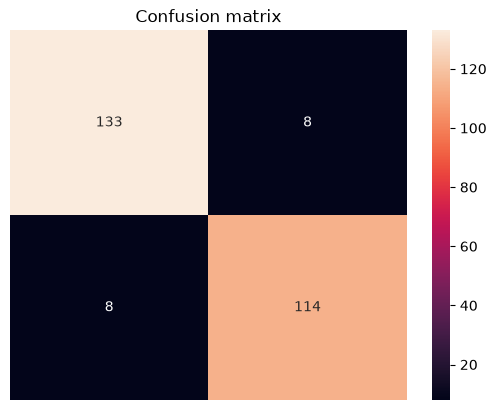

In [103]:
sns.heatmap(matrix,annot=True,fmt='d') 
plt.title('Confusion matrix')
plt.axis('off')
plt.show()

In [105]:
print(classification_report(evaluation_df['actual_class'],evaluation_df['predicted_class']))

              precision    recall  f1-score   support

         ham       0.94      0.94      0.94       141
        spam       0.93      0.93      0.93       122

    accuracy                           0.94       263
   macro avg       0.94      0.94      0.94       263
weighted avg       0.94      0.94      0.94       263



In [106]:
## Models save  
import joblib , os 
os.makedirs('models',exist_ok=True)

joblib.dump(mnb,'./models/multinomialnaivebayes.lb')
joblib.dump(bnb,'./models/bernolinaivebayes.lb')
joblib.dump(bow_obj,'./models/countvectorizer.lb')
print("Your object is saved!")
 

Your object is saved!
